In [1]:
#from google.colab import drive
#drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
#carpeta_proyecto = "/content/drive/MyDrive/MIT105_Project/inputs"
carpeta_proyecto = r"D:\Cursos\0002a_MachineLearning\MIHE\MIT105_Project\inputs"

In [7]:
import pandas as pd
import requests

### <font color = 'green'> Loading the aggregated traffic data </font>

This file has the traffic data already aggregated, by segment_id, month, day_of_week and hour. The raw data comes from the official Chicago data portal (Chicago Traffic Tracker, 2024-2026). We pulled it, aggregated it and saved it as a Parquet file, to make it faster to work with here.

Each row has the average speed and other traffic stats for one combination. We use this data to build the features and the target for the model.

In [8]:
df_agg = pd.read_parquet(f"{carpeta_proyecto}/chicago_traffic_aggregated.parquet")

In [9]:
df_agg.head()

,segment_id,month,day_of_week,hour,avg_speed,avg_bus_count,avg_message_count,n_readings
0,1,1,0,0,25.4545454545454545,1.1818181818181818,7.8181818181818182,22
1,1,1,0,1,25.2608695652173913,1.3478260869565217,6.0000000000000000,23
2,1,1,0,2,25.5625000000000000,1.3750000000000000,7.1875000000000000,16
3,1,1,0,3,26.0000000000000000,1.00000000000000000000,2.5000000000000000,2
4,1,1,0,4,25.0000000000000000,1.00000000000000000000,3.5000000000000000,2


## <font color = 'green'> Loading the segments metadata </font>

This file has the metadata for each street segment: street name, direction, from/to streets, length, and the start/end coordinates. It also comes from the official Chicago data portal and was aggregated to one row per segment_id.

We use this data to add location info to the traffic data later, in the merge step.

In [10]:
df_segments = pd.read_parquet(f"{carpeta_proyecto}/chicago_segments_metadata.parquet")

In [11]:
df_segments.head()

,segment_id,street,direction,from_street,to_street,street_heading,length,start_latitude,start_longitude,end_latitude,end_longitude
0,1,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
1,2,55th,EB,Central Park,Kedzie,W,0.5,41.793140551,-87.7136071496,41.7933767009,-87.7035554211
2,3,55th,EB,Kedzie,California,W,0.5,41.7933767009,-87.7035554211,41.7935536023,-87.693799302
3,4,55th,EB,California,Western,W,0.5,41.7935536023,-87.693799302,41.7937393759,-87.6840431555
4,5,Garfield,EB,Western,Damen,W,0.5,41.7937393759,-87.6840431555,41.7937791103,-87.6743019717


### <font color = 'green'> Loading the missing data counts </font>

This file has the count of readings with speed = -1 for each segment. This value means the sensor could not estimate a speed for that segment at that time.

We use this data to check which segments have too much missing data, before we decide which ones to drop.

In [12]:
df_missing = pd.read_parquet(f"{carpeta_proyecto}/chicago_segments_df_missing.parquet")

In [13]:
df_missing.head()

,segment_id,missing_readings
0,1,37825
1,2,26368
2,3,28913
3,4,26715
4,5,33186


### <font color = 'green'> Loading the data quality summary </font>

This file has the final quality check for each segment: the number of valid readings, the number of missing readings, and the missing percentage. It also has the list of segments with more than 90% missing data.

We use this data in the next step, to filter out the bad segments before building the model.

In [14]:
df_quality = pd.read_parquet(f"{carpeta_proyecto}/chicago_segments_quality.parquet")

In [15]:
df_quality.head()

,segment_id,valid_readings,missing_readings,total_readings,missing_pct
0,1,58774,37825,96599,39.156720
1,10,62498,34101,96599,35.301608
2,100,76329,20270,96599,20.983654
3,1000,12943,83657,96600,86.601449
4,1001,16306,80294,96600,83.120083


In [16]:
print("df_agg:", df_agg.shape)
print("df_segments:", df_segments.shape)
print("df_missing:", df_missing.shape)
print("df_quality:", df_quality.shape)

df_agg: (1873328, 8)
df_segments: (1047, 11)
df_missing: (1047, 2)
df_quality: (1046, 5)


### <font color = 'tblue'> Finding the segments to exclude: </font>

We already know some segments have too many missing readings. Here we get the list of segments with more than 90% missing data, based on the quality check we loaded before.

We will use this list in the next step, to remove these segments from the data before building the model.

In [17]:
# List of segments to exclude (more than 90% missing data)
bad_segments = df_quality[df_quality["missing_pct"] > 90]["segment_id"].tolist()
print(f"Segments to exclude: {len(bad_segments)}")

Segments to exclude: 37


### <font color = 'tblue'> Removing the bad segments from the traffic data </font>
Now we remove the 37 bad segments from the aggregated traffic data. We keep only the rows where segment_id is not in the exclude list.

This gives us a cleaner dataset, without the segments that had too little data to be reliable.

In [18]:
# Apply the filter to df_agg and df_segments
df_agg_clean = df_agg[~df_agg["segment_id"].isin(bad_segments)].copy()
print(f"df_agg: {len(df_agg)} -> {len(df_agg_clean)} rows")

df_agg: 1873328 -> 1856147 rows


### <font color = 'tblue'> Removing the bad segments from the metadata </font>

We do the same filter on the segments metadata, so it matches the cleaned traffic data. We keep only the segments that are not in the exclude list.

In [19]:
df_segments_clean = df_segments[~df_segments["segment_id"].isin(bad_segments)].copy()
print(f"df_segments: {len(df_segments)} -> {len(df_segments_clean)} rows")

df_segments: 1047 -> 1010 rows


### <font color = 'darkpink'> Merging the traffic data with the segment info </font>


Now we join the two clean dataframes together, using segment_id as the key. This adds the street name, direction, length, and coordinates to each row of traffic data.

After this, we will have one single dataframe with everything we need to build the features for the model.

In [20]:
# Merge traffic data with segment metadata, using segment_id as the key
df_model = df_agg_clean.merge(df_segments_clean, on="segment_id", how="left")

print(f"df_model shape: {df_model.shape}")
print(f"Rows with missing segment info: {df_model['street'].isna().sum()}")

df_model shape: (1856147, 18)
Rows with missing segment info: 0


In [21]:
df_model.head(6)

,segment_id,month,day_of_week,hour,avg_speed,avg_bus_count,avg_message_count,n_readings,street,direction,from_street,to_street,street_heading,length,start_latitude,start_longitude,end_latitude,end_longitude
0,1,1,0,0,25.4545454545454545,1.1818181818181818,7.8181818181818182,22,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
1,1,1,0,1,25.2608695652173913,1.3478260869565217,6.0000000000000000,23,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
2,1,1,0,2,25.5625000000000000,1.3750000000000000,7.1875000000000000,16,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
3,1,1,0,3,26.0000000000000000,1.00000000000000000000,2.5000000000000000,2,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
4,1,1,0,4,25.0000000000000000,1.00000000000000000000,3.5000000000000000,2,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496
5,1,1,0,5,25.4666666666666667,1.00000000000000000000,8.4666666666666667,15,55th,EB,Pulaski,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496


### <font color = 'darkpink'> Creating the weekend flag </font>

We add a simple flag to mark if a row happens on a weekend or not. This is useful because traffic patterns are usually different on weekends versus weekdays.

Note1: in this data, day_of_week follows the convention Sunday = 0. So weekend days are 0 (Sunday) and 6 (Saturday).

Note2: day_of_week came from the Parquet file as text, so we convert it to a number first. The convention is Sunday = 0 and Saturday = 6 (from the date_extract_dow function used when we built this data).

In [22]:
# Convert day_of_week to integer (it loaded as text from Parquet)
df_model["day_of_week"] = df_model["day_of_week"].astype(int)

# day_of_week convention: Sunday = 0, Saturday = 6
df_model["is_weekend"] = df_model["day_of_week"].isin([0, 6]).astype(int)

print(df_model["is_weekend"].value_counts())

0    1340702
1     515445
Name: is_weekend, dtype: int64


### <font color = 'darkpink'> Creating the rush hour flag </font>

We add a flag to mark if a row happens during rush hour. We use the typical rush hour times: 7 to 9 in the morning, and 4 to 6 in the afternoon.

Note: hour also came from the Parquet file as text, so we convert it to a number first.

In [23]:
print(df_model["hour"].unique())
print(df_model["hour"].dtype)

['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' '10' '11' '12' '13' '14' '15'
 '16' '17' '18' '19' '20' '21' '22' '23']
object


In [24]:
# Convert hour to integer (it loaded as text from Parquet)
df_model["hour"] = df_model["hour"].astype(int)

# Rush hour: 7-9 AM and 4-6 PM
rush_hours = [7, 8, 9, 16, 17, 18]
df_model["is_rush_hour"] = df_model["hour"].isin(rush_hours).astype(int)

print(df_model["is_rush_hour"].value_counts())

0    1352051
1     504096
Name: is_rush_hour, dtype: int64


### <font color = 'darkpink'> Checking the average speed values </font>


Before we build the congestion levels, we convert avg_speed to a number and look at its range. This helps us confirm the values make sense before we split them into categories.

In [25]:
print(df_model["avg_speed"].describe())
print(df_model["avg_speed"].dtype)

count                 1856147
unique                  40633
top       25.0000000000000000
freq                    14585
Name: avg_speed, dtype: object
object


In [26]:
# Convert avg_speed to float (it loaded as text from Parquet)
df_model["avg_speed"] = df_model["avg_speed"].astype(float)

print(df_model["avg_speed"].describe())

count    1.856147e+06
mean     2.516575e+01
std      5.910734e+00
min      0.000000e+00
25%      2.183784e+01
50%      2.438776e+01
75%      2.712121e+01
max      5.625000e+01
Name: avg_speed, dtype: float64


# <font color = 'darkblue'> Finding balanced thresholds for congestion levels </font>


To define the congestion levels, we use the actual distribution of avg_speed in this dataset. We get the 33rd and 66th percentile, so each congestion level (Heavy, Moderate, Free Flow) ends up with a similar number of rows. This way the categories reflect real traffic patterns in Chicago, not a generic rule.

In [27]:
p33 = df_model["avg_speed"].quantile(0.33)
p66 = df_model["avg_speed"].quantile(0.66)

print(f"33rd percentile: {p33:.2f} mph")
print(f"66th percentile: {p66:.2f} mph")

33rd percentile: 22.70 mph
66th percentile: 26.00 mph


# <font color = 'orange'>Creating the congestion level (the target)  </font>

This is the value we want the model to predict. We use the 33rd and 66th percentile of avg_speed to split the data into three congestion levels, so each level has a similar number of rows:

* Heavy: average speed below 22.70 mph
* Moderate: average speed between 22.70 and 26.00 mph
* Free Flow: average speed above 26.00 mph

In [28]:
def congestion_level(speed):
    if speed < 22.70:
        return "Heavy"
    elif speed <= 26.00:
        return "Moderate"
    else:
        return "Free Flow"

df_model["congestion_level"] = df_model["avg_speed"].apply(congestion_level)

print(df_model["congestion_level"].value_counts())

Free Flow    627663
Moderate     616508
Heavy        611976
Name: congestion_level, dtype: int64


### <font color = 'darkpink'> Checking data types before the EDA </font>

Before we explore the geographic features, we check their data types. Some columns from this Parquet file load as text instead of numbers, so we confirm this first to avoid wrong results later.

In [29]:
df_model.head()

,segment_id,month,day_of_week,hour,avg_speed,avg_bus_count,avg_message_count,n_readings,street,direction,...,to_street,street_heading,length,start_latitude,start_longitude,end_latitude,end_longitude,is_weekend,is_rush_hour,congestion_level
0,1,1,0,0,25.454545,1.1818181818181818,7.8181818181818182,22,55th,EB,...,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496,1,0,Moderate
1,1,1,0,1,25.260870,1.3478260869565217,6.0000000000000000,23,55th,EB,...,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496,1,0,Moderate
2,1,1,0,2,25.562500,1.3750000000000000,7.1875000000000000,16,55th,EB,...,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496,1,0,Moderate
3,1,1,0,3,26.000000,1.00000000000000000000,2.5000000000000000,2,55th,EB,...,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496,1,0,Moderate
4,1,1,0,4,25.000000,1.00000000000000000000,3.5000000000000000,2,55th,EB,...,Central Park,W,0.5,41.7930671862,-87.7231602513,41.793140551,-87.7136071496,1,0,Moderate


In [30]:
geo_cols = ["start_latitude", "start_longitude", "end_latitude", "end_longitude", "length"]
print(df_model[geo_cols].dtypes)

start_latitude     object
start_longitude    object
end_latitude       object
end_longitude      object
length             object
dtype: object


### <font color = 'darkpink'> Converting geographic columns and checking correlation </font>

We convert these columns to numbers, since they loaded as text from Parquet. Then we check the correlation between them, to see if the start and end coordinates carry mostly the same information.

In [31]:
geo_cols = ["start_latitude", "start_longitude", "end_latitude", "end_longitude", "length"]
df_model[geo_cols] = df_model[geo_cols].astype(float)

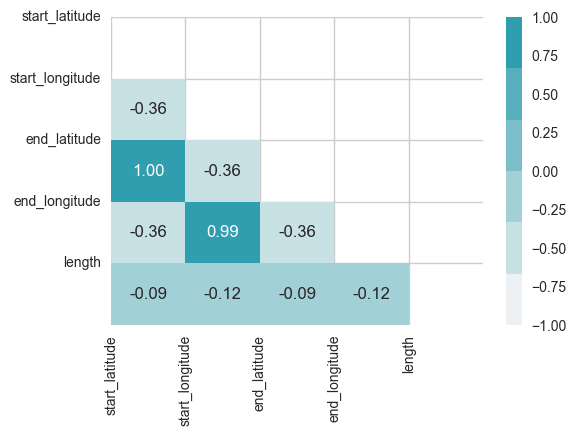

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

corr = df_model[geo_cols].corr()
fig, ax = plt.subplots(figsize=(6, 4))

cmap = sns.light_palette((210, 90, 60), input="husl")
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

#ax.matshow(corr)
sns.heatmap(corr,mask=mask,cmap=cmap,annot=True,fmt=".2f",vmin=-1,vmax=1);
plt.xticks(range(len(corr.columns)), corr.columns);
plt.yticks(range(len(corr.columns)), corr.columns);
plt.show()

What the correlation matrix tells us

The heatmap shows two very strong correlations:

start_latitude vs end_latitude: 1.00
start_longitude vs end_longitude: 0.99

This happens because street segments in this dataset are short. The point where a segment starts and the point where it ends are almost in the same place on the map. So the start and end coordinates are basically repeating the same information twice.

The other correlations are weak. Latitude and longitude show a small negative value (-0.36), which only reflects how the Chicago street grid is laid out. And length has almost no correlation with any of the coordinates (-0.09 to -0.12), which makes sense: a long segment can be in any part of the city.

Decision based on this result: we will not use the geographic columns (start_latitude, start_longitude, end_latitude, end_longitude) as features for the model. We keep them in the dataset only for the map, both in this exploratory analysis and later in the deployed app, where the user will pick a segment visually. If we used them as model features, the model would basically memorize each segment instead of learning general traffic patterns, and that would hurt how well it works on new or changing conditions.

### <font color = 'darkpink'> Checking if direction and street_heading give the same information </font>

These two columns are both categorical, so instead of correlation we use a crosstab (how many rows have each combination). If one almost always matches the other, they carry the same information and we only need one.

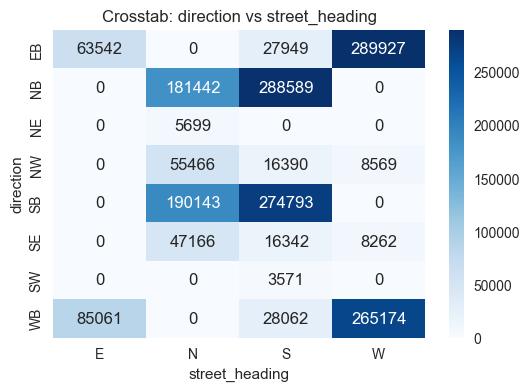

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

ct = pd.crosstab(df_model["direction"], df_model["street_heading"])

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("Crosstab: direction vs street_heading")
plt.show()

What the crosstab tells us

The heatmap shows how direction (where the traffic flows) and street_heading (how the street is laid out on the map) combine in the data.

The two columns are not the same thing:

direction with values EB, WB, NB, SB appears mixed with different street_heading values. For example, EB traffic shows up with heading W, heading E, and heading S. If both columns meant the same thing, EB would only appear with one heading.
NB and SB both split between heading N and heading S, almost evenly. These are probably different parts of the same corridor, which can have different traffic patterns on each side.
Diagonal directions (NE, NW, SE, SW) are rare in the data. Most traffic in Chicago moves N/S or E/W.

So the two columns give different information:

direction = which way the traffic is moving.
street_heading = how the street itself is oriented.

They are related, but not the same. A street that runs N-S will not have EB traffic, but inside that general rule, each column still adds something the other does not.

Decision based on this result: we keep both direction and street_heading as features for the model. Each one brings its own signal, and dropping one would lose information about the segment.

### <font color = 'green'> One-hot encoding for direction and street_heading </font>

The model needs numbers, not text, to work with categorical features. We convert direction and street_heading into one column per category, with 1 if the row belongs to that category and 0 otherwise. For example, direction = "NB" becomes a column direction_NB with value 1 for all northbound rows, and 0 for the rest.

In [34]:
# One-hot encoding for the two categorical features
df_model = pd.get_dummies(df_model, columns=["direction", "street_heading"], dtype=int)

In [35]:
# Check the new columns
new_cols = [c for c in df_model.columns if c.startswith("direction_") or c.startswith("street_heading_")]
print(f"New columns created: {len(new_cols)}")
print(new_cols)
print(f"df_model shape: {df_model.shape}")

New columns created: 12
['direction_EB', 'direction_NB', 'direction_NE', 'direction_NW', 'direction_SB', 'direction_SE', 'direction_SW', 'direction_WB', 'street_heading_E', 'street_heading_N', 'street_heading_S', 'street_heading_W']
df_model shape: (1856147, 31)


### <font color = 'orange'> Preparing features and target, then splitting the data </font>

We separate the dataset into features (X, what the model uses to predict) and target (y, what we want to predict). We use an 80/20 split, keeping the same proportion of each congestion level in both train and test, so neither side has too many or too few of any class.

In [36]:
from sklearn.model_selection import train_test_split

# Define the final feature columns
feature_cols = [
    "month", "day_of_week", "hour", "is_weekend", "is_rush_hour", "length",
    "direction_EB", "direction_NB", "direction_NE", "direction_NW",
    "direction_SB", "direction_SE", "direction_SW", "direction_WB",
    "street_heading_E", "street_heading_N", "street_heading_S", "street_heading_W"
]

# Make sure month is a number (it may have loaded as text from Parquet)
df_model["month"] = df_model["month"].astype(int)

X = df_model[feature_cols]
y = df_model["congestion_level"]

# Random split 80/20, stratified by target to keep class balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [37]:
df_model.describe()

,month,day_of_week,hour,avg_speed,length,start_latitude,start_longitude,end_latitude,end_longitude,is_weekend,...,direction_NE,direction_NW,direction_SB,direction_SE,direction_SW,direction_WB,street_heading_E,street_heading_N,street_heading_S,street_heading_W
count,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,...,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06,1.856147e+06
mean,6.508556e+00,3.018230e+00,1.214784e+01,2.516575e+01,5.273599e-01,4.184885e+01,-8.767943e+01,4.184892e+01,-8.767944e+01,2.776962e-01,...,3.070339e-03,4.332900e-02,2.504845e-01,3.866612e-02,1.923878e-03,2.038077e-01,8.005993e-02,2.585550e-01,3.532565e-01,3.081286e-01
std,3.453367e+00,1.985772e+00,6.633702e+00,5.910734e+00,1.746703e-01,8.286098e-02,5.685530e-02,8.295742e-02,5.688825e-02,4.478629e-01,...,5.532552e-02,2.035967e-01,4.332922e-01,1.927980e-01,4.381983e-02,4.028277e-01,2.713860e-01,4.378406e-01,4.779817e-01,4.617201e-01
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e-02,4.165897e+01,-8.783671e+01,4.165901e+01,-8.783671e+01,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.000000e+00,1.000000e+00,7.000000e+00,2.183784e+01,5.000000e-01,4.178702e+01,-8.772437e+01,4.178675e+01,-8.772444e+01,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,7.000000e+00,3.000000e+00,1.200000e+01,2.438776e+01,5.000000e-01,4.185752e+01,-8.766848e+01,4.185752e+01,-8.766848e+01,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.000000e+01,5.000000e+00,1.800000e+01,2.712121e+01,5.300000e-01,4.191032e+01,-8.763544e+01,4.191032e+01,-8.763526e+01,1.000000e+00,...,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.200000e+01,6.000000e+00,2.300000e+01,5.625000e+01,1.535624e+00,4.201283e+01,-8.753505e+01,4.201283e+01,-8.753542e+01,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [38]:
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"\ny_train distribution:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\ny_test distribution:")
print(y_test.value_counts(normalize=True).round(3))

X_train: (1484917, 18)
X_test:  (371230, 18)

y_train distribution:
Free Flow    0.338
Moderate     0.332
Heavy        0.330
Name: congestion_level, dtype: float64

y_test distribution:
Free Flow    0.338
Moderate     0.332
Heavy        0.330
Name: congestion_level, dtype: float64


### <font color = 'orange'> Scaling the numeric features </font>

For KNN and Logistic Regression, the numeric features need to be on a similar scale, so that no feature dominates just because its values are bigger. We scale only the four continuous numeric columns (month, day_of_week, hour, length). The binary flags and one-hot columns stay as they are.

The scaler is fit using only the training data, and then applied to both training and test sets. This avoids leaking information from the test set into the training.

In [39]:
from sklearn.preprocessing import StandardScaler

# Columns to scale (only continuous numeric)
cols_to_scale = ["month", "day_of_week", "hour", "length"]

# Copy to avoid changing the original splits
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit the scaler ONLY on training data
scaler = StandardScaler()
X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

# Apply the same transformation to the test set (no re-fit)
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [40]:
# Quick check: scaled columns should have mean ~0 and std ~1 in train
print("After scaling (train set):")
print(X_train_scaled[cols_to_scale].describe().loc[["mean", "std"]].round(3))

After scaling (train set):
      month  day_of_week  hour  length
mean    0.0          0.0   0.0    -0.0
std     1.0          1.0   1.0     1.0


In [45]:
# Save the fitted StandardScaler for deployment use
# The scaler must be saved alongside the model, otherwise the Streamlit app
# would have to apply raw inputs to a model trained on scaled features (training-serving skew).

import joblib
import os

scaler_path = "scaler.pkl"
joblib.dump(scaler, scaler_path)

# Confirm the file was created
if os.path.exists(scaler_path):
    size_kb = os.path.getsize(scaler_path) / 1024
    print(f"Scaler saved: {os.path.abspath(scaler_path)}")
    print(f"Size: {size_kb:.2f} KB")

# Quick sanity check: show the scaler stats so we can verify they match what the app will apply
print("\nScaler statistics (learned from X_train):")
for col, mean, std in zip(scaler.feature_names_in_, scaler.mean_, scaler.scale_):
    print(f"  {col}: mean={mean:.4f}, std={std:.4f}")

Scaler saved: D:\Cursos\0002a_MachineLearning\MIHE\MIT105_Project\scaler.pkl
Size: 1.02 KB

Scaler statistics (learned from X_train):
  month: mean=6.5074, std=3.4525
  day_of_week: mean=3.0188, std=1.9856
  hour: mean=12.1437, std=6.6316
  length: mean=0.5274, std=0.1748


### <font color = 'orange'> Building the train and test dataframes for PyCaret</font>

PyCaret needs the target column inside the same dataframe as the features. So we take the scaled features and add the target column back in, for both train and test sets.

In [41]:
# Build train and test dataframes (scaled features + target in one dataframe)
train_df = X_train_scaled.copy()
train_df["congestion_level"] = y_train.values

test_df = X_test_scaled.copy()
test_df["congestion_level"] = y_test.values

In [43]:

print(f"train_df shape: {train_df.shape}")
print(f"test_df shape:  {test_df.shape}")
print(f"\nColumns in train_df:")
print(train_df.columns.tolist())

train_df shape: (1484917, 19)
test_df shape:  (371230, 19)

Columns in train_df:
['month', 'day_of_week', 'hour', 'is_weekend', 'is_rush_hour', 'length', 'direction_EB', 'direction_NB', 'direction_NE', 'direction_NW', 'direction_SB', 'direction_SE', 'direction_SW', 'direction_WB', 'street_heading_E', 'street_heading_N', 'street_heading_S', 'street_heading_W', 'congestion_level']


### <font color = 'orange'> Taking a stratified sample for the model comparison </font>

Comparing many models on 1.4 million rows would take too long. We take a smaller sample of 60,000 rows from the training set, keeping the same proportion of each congestion level. This is enough data to compare models reliably, and much faster to run.

The test set stays as it is (371,230 rows), so the final evaluation of the winning model is still done on real, unseen data.



In [42]:
from sklearn.model_selection import train_test_split

# Stratified sample of 60,000 rows from train, keeping class proportions
sample_df, _ = train_test_split(
    train_df,
    train_size=60_000,
    stratify=train_df["congestion_level"],
    random_state=42
)

In [43]:

print(f"sample_df shape: {sample_df.shape}")
print(f"\nTarget distribution in sample:")
print(sample_df["congestion_level"].value_counts(normalize=True).round(3))

sample_df shape: (60000, 19)

Target distribution in sample:
Free Flow    0.338
Moderate     0.332
Heavy        0.330
Name: congestion_level, dtype: float64


# <font color = 'Orange'> AutoML with PyCaret </font>

PyCaret is an AutoML library that trains and compares many classification models with just a few lines of code. It gives us a table with the main metrics (accuracy, F1, recall, etc.) for each model, so we can pick the best one with evidence, instead of testing models one by one by hand.


In [44]:
import pycaret
print(pycaret.__version__)

3.1.0


## <font color = 'darkpink'> Setting up the experiment with PyCaret </font>


PyCaret needs the training data and the test data as full dataframes, with the target column included. We already have sample_df (60,000 rows for training) and test_df (371,230 rows for the final evaluation).

We tell PyCaret not to normalize or encode the data again, because we already did that by hand before (StandardScaler on the numeric columns, one-hot encoding on direction and street_heading). If we let PyCaret do it again, the data would be transformed twice.

In [46]:
from pycaret.classification import setup, compare_models

exp = setup(
    data=sample_df,
    test_data=test_df,
    target="congestion_level",
    session_id=42,
    normalize=False,
    fix_imbalance=False
)

,Description,Value
0,Session id,42
1,Target,congestion_level
2,Target type,Multiclass
3,Target mapping,"Free Flow: 0, Heavy: 1, Moderate: 2"
4,Original data shape,"(431230, 19)"
5,Transformed data shape,"(431230, 19)"
6,Transformed train set shape,"(60000, 19)"
7,Transformed test set shape,"(371230, 19)"
8,Numeric features,18
9,Preprocess,True


### <font color = 'green'> Comparing many models with PyCaret </font>

We ask PyCaret to train and compare many classification models at the same time. For each model, PyCaret runs 10-fold cross-validation on the training sample, and reports the average of the main metrics (Accuracy, Recall, Precision, F1, and others). The result is a leaderboard, sorted by F1 score, so we can see which models work best for this problem.

We sort by F1 because the three congestion classes are balanced, but F1 is a safer metric than accuracy. It balances precision and recall, so it reflects both how often the model is right and how well it covers each class.

In [47]:
# Train and compare many models with 10-fold cross-validation
# This may take 10-30 minutes depending on the machine
best_models = compare_models(sort="F1", n_select=3)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
xgboost,Extreme Gradient Boosting,0.5972,0.7996,0.5972,0.5949,0.5957,0.3958,0.3961,0.3870
catboost,CatBoost Classifier,0.5934,0.7946,0.5934,0.5912,0.5919,0.3900,0.3903,5.8490
lightgbm,Light Gradient Boosting Machine,0.5919,0.7945,0.5919,0.5890,0.5897,0.3879,0.3884,0.6190
gbc,Gradient Boosting Classifier,0.5455,0.7499,0.5455,0.5397,0.5406,0.3183,0.3194,3.0570
rf,Random Forest Classifier,0.5313,0.7135,0.5313,0.5299,0.5305,0.2969,0.2970,1.2300
dt,Decision Tree Classifier,0.5266,0.6686,0.5266,0.5232,0.5236,0.2896,0.2904,0.0580
et,Extra Trees Classifier,0.5043,0.6640,0.5043,0.4997,0.5006,0.2561,0.2569,1.2880
ada,Ada Boost Classifier,0.5051,0.6941,0.5051,0.4914,0.4893,0.2573,0.2620,0.3110
lda,Linear Discriminant Analysis,0.4857,0.6799,0.4857,0.4744,0.4745,0.2283,0.2310,0.0670
knn,K Neighbors Classifier,0.4805,0.6678,0.4805,0.4737,0.4723,0.2202,0.2225,0.8750


## <font color = 'green'> Finalizing the top 3 models </font>

We take the three best models from the comparison and re-train each one with the full training set (1,484,917 rows), not just the 60,000-row sample we used before. This gives us the final production-ready version of each model, with all the data available.

In [49]:
# Finalize each of the top 3 models (retrain on the full training set)

from pycaret.classification import finalize_model, predict_model, save_model

final_xgb = finalize_model(best_models[0])
final_catboost = finalize_model(best_models[1])
final_lightgbm = finalize_model(best_models[2])

print("Top 3 models finalized and ready for evaluation on the test set.")

Top 3 models finalized and ready for evaluation on the test set.


## <font color = 'green'> Evaluating the three models on the full test set </font>

We now test each model on the 371,230 rows that were kept apart from training. This gives us the honest performance of each model on data it has never seen. We compare the three to pick the final winner for deployment.

In [50]:
print("=== XGBoost ===")
pred_xgb = predict_model(final_xgb, data=test_df)

=== XGBoost ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extreme Gradient Boosting,0.6131,0.8144,0.6131,0.6109,0.6116,0.4197,0.4200


In [51]:
print("=== CatBoost ===")
pred_catboost = predict_model(final_catboost, data=test_df)

=== CatBoost ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,CatBoost Classifier,0.6154,0.8170,0.6154,0.6133,0.6140,0.4231,0.4233


In [52]:
print("=== LightGBM ===")
pred_lightgbm = predict_model(final_lightgbm, data=test_df)

=== LightGBM ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Light Gradient Boosting Machine,0.6020,0.8026,0.6020,0.6005,0.6008,0.4030,0.4033


## <font color = 'darkpink'> Confusion matrix for each model </font>

The confusion matrix shows how the model’s predictions compare with the real class. Rows are the actual congestion level, columns are the prediction. The diagonal is correct, everything else is a mistake.

We check if the model makes “soft” mistakes (confusing neighbor classes like Heavy with Moderate) or “hard” mistakes (confusing Heavy with Free Flow, which is a worse error for traffic management).

In [53]:
from pycaret.classification import plot_model

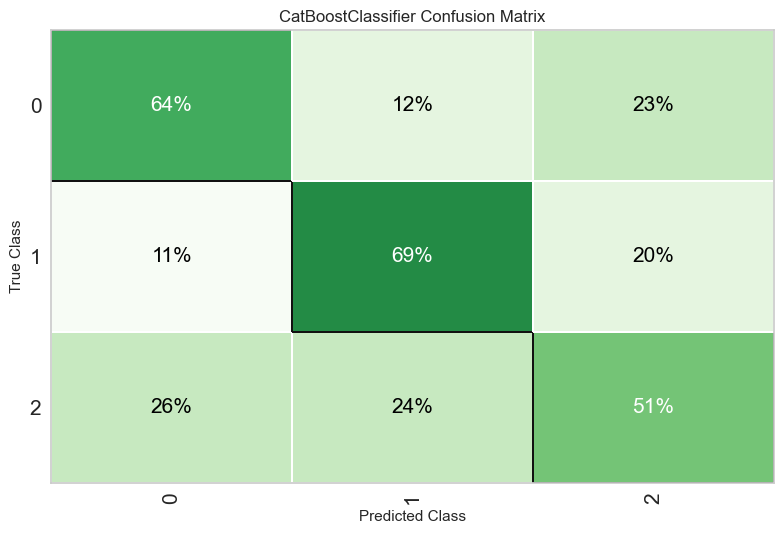

In [54]:
# Confusion matrix for CatBoost (the winner)
plot_model(final_catboost, plot='confusion_matrix', plot_kwargs={'percent': True})

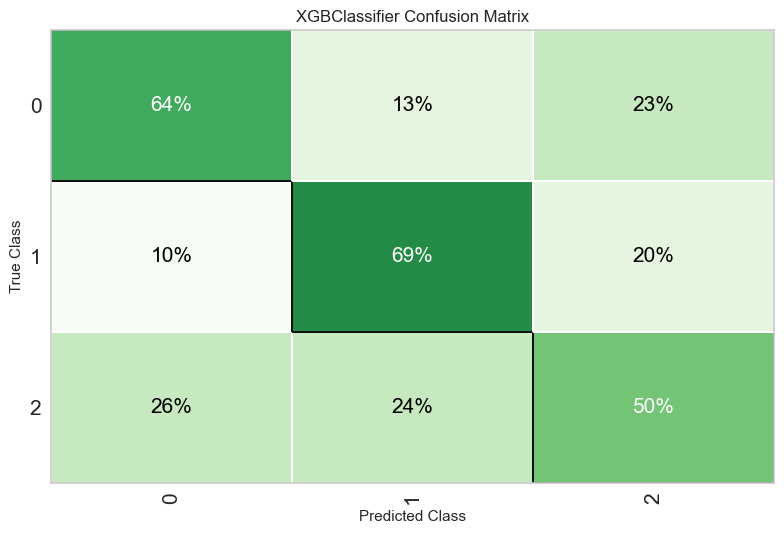

In [55]:
# Confusion matrix for XGBoost (second place)
plot_model(final_xgb, plot='confusion_matrix', plot_kwargs={'percent': True})

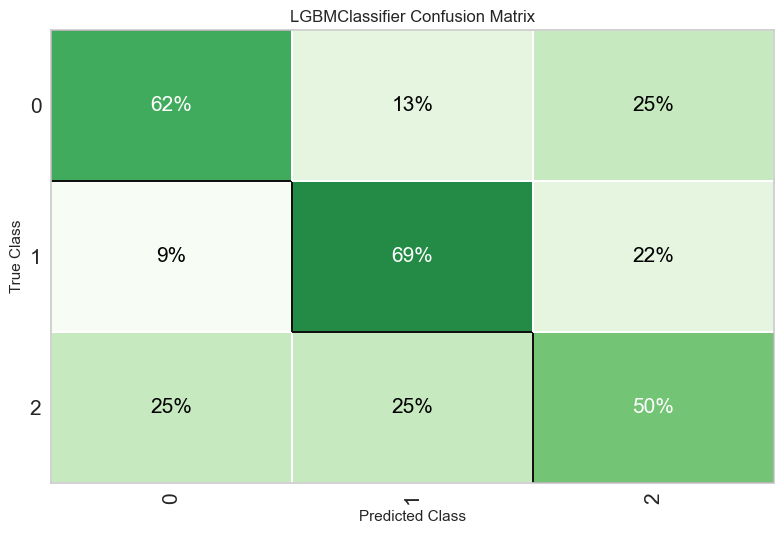

In [56]:
# Confusion matrix for LightGBM (third place)
plot_model(final_lightgbm, plot='confusion_matrix', plot_kwargs={'percent': True})

# <font color = 'darkpink'> Saving the winning model for deployment </font>

We save the final CatBoost model to a file. This way we can load it later in the Streamlit app without having to train again. The file keeps the model and the full pipeline, so it is ready to predict on new data.

In [58]:
# Confirm the current working directory
import os
print(f"Current working directory: {os.getcwd()}")

Current working directory: D:\Cursos\0002a_MachineLearning\MIHE\MIT105_Project


In [59]:
# Save the winning CatBoost model for later use in Streamlit
save_model(final_catboost, "catboost_congestion_model")

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('label_encoding',
                  TransformerWrapperWithInverse(exclude=None, include=None,
                                                transformer=LabelEncoder())),
                 ('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['month', 'day_of_week', 'hour',
                                              'is_weekend', 'is_rush_hour',
                                              'length', 'direction_EB',
                                              'direction_NB', 'direction_NE',
                                              'direction_NW', 'direction_SB'...
                                                               verbose='deprecated'))),
                 ('categorical_imputer',
                  TransformerWrapper(exclude=None, include=[],
                                     transformer=SimpleImputer(add_indicator=False,
                    

In [60]:
# Confirm the file was created
file_path = "catboost_congestion_model.pkl"
if os.path.exists(file_path):
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"\n✓ File saved: {os.path.abspath(file_path)}")
    print(f"  Size: {size_mb:.2f} MB")


✓ File saved: D:\Cursos\0002a_MachineLearning\MIHE\MIT105_Project\catboost_congestion_model.pkl
  Size: 2.02 MB


Pruebas

In [1]:
import pandas as pd
from pycaret.classification import load_model, predict_model

model = load_model("catboost_congestion_model")

test_row = pd.DataFrame([{
    "month": 11, "day_of_week": 1, "hour": 3,
    "is_weekend": 0, "is_rush_hour": 0, "length": 0.5,
    "direction_EB": 1, "direction_NB": 0, "direction_NE": 0, "direction_NW": 0,
    "direction_SB": 0, "direction_SE": 0, "direction_SW": 0, "direction_WB": 0,
    "street_heading_E": 0, "street_heading_N": 0, "street_heading_S": 0, "street_heading_W": 1,
}])

pred = predict_model(model, data=test_row)
print(pred[["prediction_label", "prediction_score"]])

Transformation Pipeline and Model Successfully Loaded
  prediction_label  prediction_score
0            Heavy            0.8473


In [44]:
# Diagnóstico: probar el modelo con filas reales ya escaladas
# Tomamos 3 filas del test set, una de cada clase, 
# para ver si el modelo distingue cuando los inputs vienen bien escalados

# Reconstruir test_df con el target (ya lo tenías construido en línea 389,
# pero por si acaso no está en memoria)
test_df_full = X_test_scaled.copy()
test_df_full["congestion_level"] = y_test.values

# Tomar 1 fila real de cada clase
sample_heavy = test_df_full[test_df_full["congestion_level"] == "Heavy"].iloc[0:1]
sample_moderate = test_df_full[test_df_full["congestion_level"] == "Moderate"].iloc[0:1]
sample_freeflow = test_df_full[test_df_full["congestion_level"] == "Free Flow"].iloc[0:1]

# Juntar las 3 filas para predecir en bloque
diagnostic_sample = pd.concat([sample_heavy, sample_moderate, sample_freeflow])

# Separar features (sin target) para pasárselas al modelo
diagnostic_features = diagnostic_sample.drop(columns=["congestion_level"])

# Predecir con el modelo cargado
pred_diagnostic = predict_model(model, data=diagnostic_features)

# Comparar real vs predicho
result = pd.DataFrame({
    "real": diagnostic_sample["congestion_level"].values,
    "predicho": pred_diagnostic["prediction_label"].values,
    "confianza": pred_diagnostic["prediction_score"].values
})
print(result)

        real   predicho  confianza
0      Heavy   Moderate     0.4591
1   Moderate   Moderate     0.4510
2  Free Flow  Free Flow     0.5611
